In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv(".venv/Lib/data/LoanApprovalPrediction.csv")


In [2]:
print(data.head())
print("\nColumn Data types:")
print(data.dtypes)

print("\nCategorical columns:")
print(data.select_dtypes(include=["object"]).columns.tolist())

print("\nNumber of categorical columns:")
print(len(data.select_dtypes(include=["object"]).columns))

    Loan_ID Gender Married  Dependents     Education Self_Employed  \
0  LP001002   Male      No         0.0      Graduate            No   
1  LP001003   Male     Yes         1.0      Graduate            No   
2  LP001005   Male     Yes         0.0      Graduate           Yes   
3  LP001006   Male     Yes         0.0  Not Graduate            No   
4  LP001008   Male      No         0.0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             

C:\Users\brand\AppData\Local\Temp\ipykernel_4944\3267421295.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(data.select_dtypes(include=["object"]).columns.tolist())
C:\Users\brand\AppData\Local\Temp\ipykernel_4944\3267421295.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_gu

In [3]:
data.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


***Data Preprocessing and Visualization***

In [4]:
#Get the number of columns of object datatype
obj = (data.dtypes == 'str')
print("Categorical variables:", len(list(obj[obj].index)))

Categorical variables: 7


In [5]:
#Dropping the Loan_ID column
data.drop(['Loan_ID'], axis=1, inplace=True)

C:\Users\brand\AppData\Local\Temp\ipykernel_4944\2764036197.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(['Loan_ID'], axis=1, inplace=True)


Visualizing all the unique values in columns using barplot. Shows which value is dominating per the dataset.

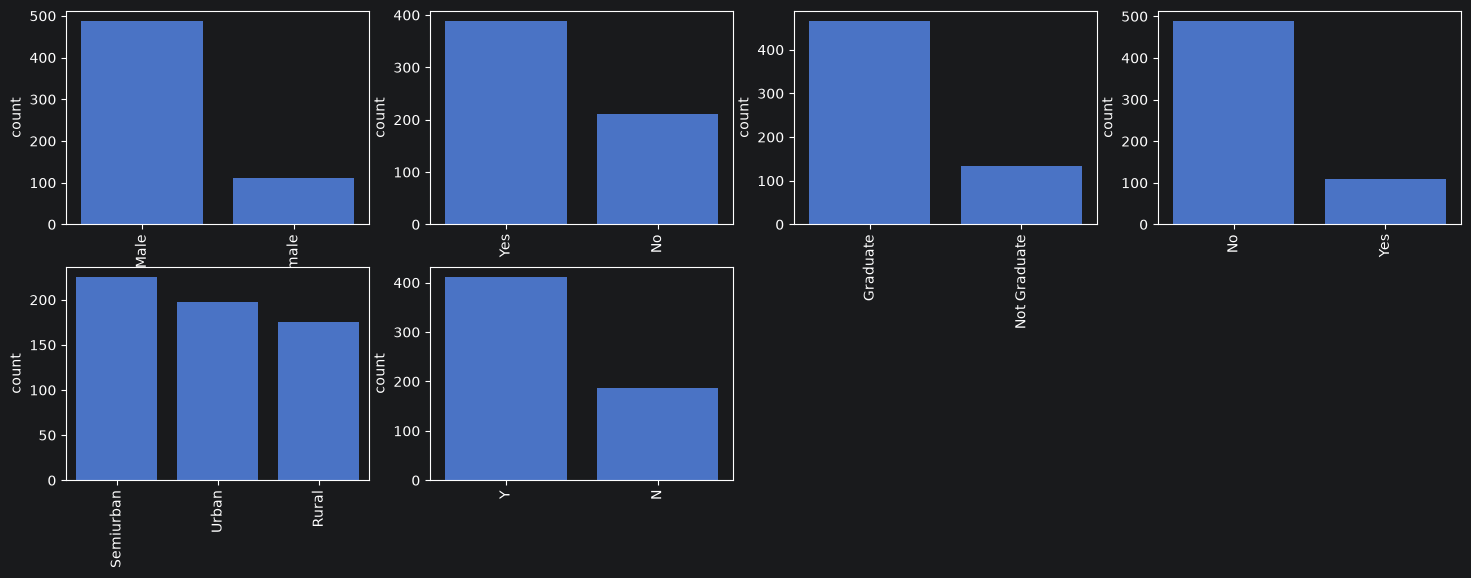

In [6]:
obj = (data.dtypes == 'str')
object_cols = list(obj[obj].index)
plt.figure(figsize=(18,36))
index = 1

for col in object_cols:
    y= data[col].value_counts()
    plt.subplot(11,4,index)
    plt.xticks(rotation=90)
    sns.barplot(x=list(y.index), y=y)
    index +=1

Since all the categorical values are binary so we can use Label Encoder for all such columns and the values will  change into *int* datatype.

In [7]:
#Import Label encoder
from sklearn import preprocessing
#label_encoder object knows how to understand word labels
label_encoder = preprocessing.LabelEncoder()
obj = (data.dtypes == 'str')
for col in list(obj[obj].index):
    data[col] = label_encoder.fit_transform(data[col])


In [8]:
#Find the number of columns with datatype == object
obj = (data.dtypes == 'str')
print("Categorical variables:", len(list(obj[obj].index)))

Categorical variables: 0


<Axes: >

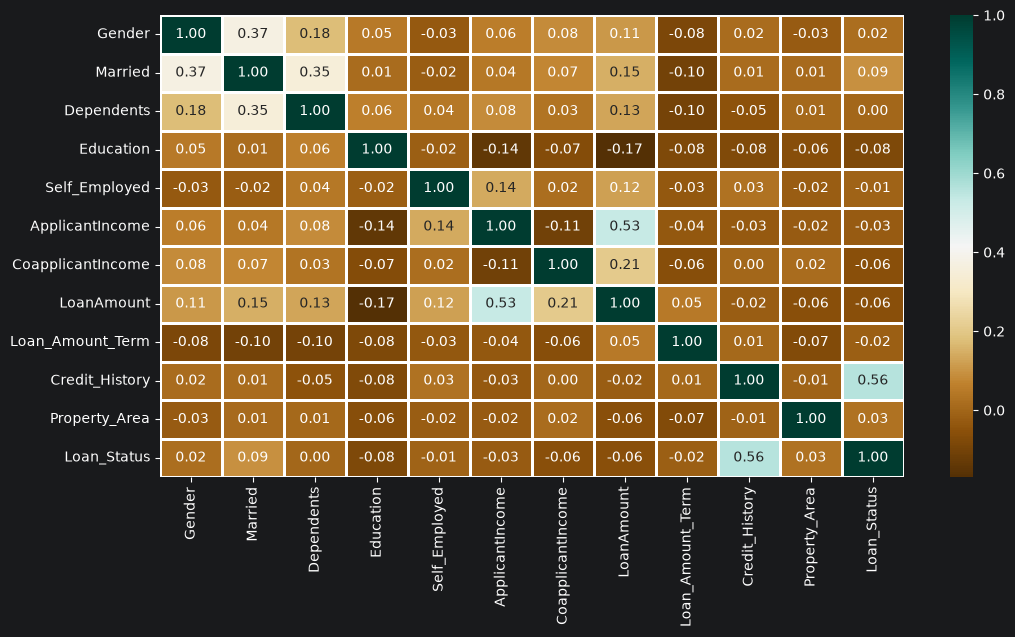

In [9]:
plt.figure(figsize=(12,6))
sns.heatmap(data.corr(),cmap='BrBG',fmt='.2f', linewidths=2,annot=True)

The heatmap above shows that the Credit_history has a high impact on the Loan_status.

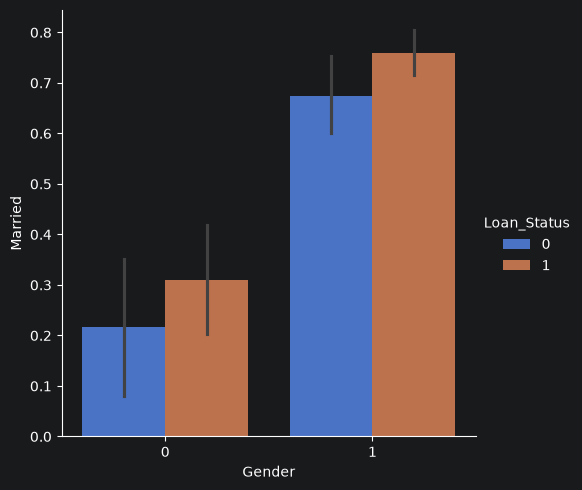

In [10]:
sns.catplot(x="Gender", y = "Married", hue = "Loan_Status", kind = "bar", data = data)

The plot above visualize the Gender and martial Status of the applicant.

Next any missing values in the data set are found.

In [11]:
for col in data.columns:
    data[col] = data[col].fillna(data[col].mean())

data.isna().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

Since no missing values are present, then we must proceed to model training.

In [12]:
#Splitting Dataset
from sklearn.model_selection import train_test_split

X = data.drop(['Loan_Status'], axis=1)
Y = data['Loan_Status']
X.shape,Y.shape

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.4, random_state = 0)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((358, 11), (240, 11), (358,), (240,))

Since this is a classification problem, we will be using these models:
- KNeighbors Classifiers
- Random Forest Classifiers
- Support Vector Classifiers (SVC)
- Logistics Regression

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn import metrics

knn = KNeighborsClassifier(n_neighbors=3)
rfc = RandomForestClassifier(n_estimators = 7,
                             criterion = 'entropy',
                             random_state =7)
svc = SVC()
lc = LogisticRegression()

# making predictions on the training set
for clf in (rfc, knn, svc,lc):
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_train)
    print("Accuracy score of ",
          clf.__class__.__name__,
          "=",100*metrics.accuracy_score(Y_train,
                                         Y_pred))

Accuracy score of  RandomForestClassifier = 97.48603351955308
Accuracy score of  KNeighborsClassifier = 81.00558659217877
Accuracy score of  SVC = 71.22905027932961
Accuracy score of  LogisticRegression = 81.00558659217877


C:\Users\brand\PycharmProjects\LoanApprovalPredictions\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
# making predictions on the testing set
for clf in (rfc, knn, svc,lc):
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_test)
    print("Accuracy score of ",
          clf.__class__.__name__,"=",
          100*metrics.accuracy_score(Y_test,
                                     Y_pred))

Accuracy score of  RandomForestClassifier = 74.58333333333333
Accuracy score of  KNeighborsClassifier = 61.66666666666667
Accuracy score of  SVC = 65.41666666666667
Accuracy score of  LogisticRegression = 80.41666666666667


C:\Users\brand\PycharmProjects\LoanApprovalPredictions\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
